<a href="https://www.kaggle.com/code/qwerty29544/ml-1-classic-ml-classification?scriptVersionId=361241417" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Классификация и восстановление вероятности
## Удовлетворён ли пассажир перелётом?

Разберём решение табличной задачи классификации на данных **Kaggle Playground Series S6E10 — Predicting Airline Satisfaction**. 

1. Посмотрим на данные и подготовим признаки,
2. Затем напишем сигмоидальную модель на NumPy и сравним её с моделями `sklearn`.
3. В конце получим классы и сохраним вероятности для отправки на Kaggle.

- В выборке `train.csv` известен ответ `satisfaction`: `True` означает положительный класс, `False` — отрицательный.
- У каждого пассажира будем оценивать $P(Y=1\mid X=x)$, а не просто выдавать ноль или единицу.
- По условиям соревнования качество оценивается по **ROC-AUC**, и в `submission.csv` нужны именно вероятности.
- Самописная модель будет обучаться как с MSE, так и с log loss. Проверим, как выбор функции потерь влияет на вероятности и качество классификации.

In [1]:
# %pip install numpy pandas matplotlib scikit-learn scipy threadpoolctl

In [2]:
from pathlib import Path
from time import perf_counter
import json
import platform

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import sklearn
import scipy

from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score, precision_recall_curve,
    log_loss, brier_score_loss, accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.calibration import calibration_curve

# Размеры графиков близки к исходному блокноту.
mpl.rcParams.update({
    "figure.figsize": (7, 5),
    "figure.dpi": 128,
    "font.size": 14,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 30)
sklearn.set_config(display="text")

## Настройки эксперимента

In [3]:
SEED = 42
FULL_REFIT = True
EPOCHS = 120
BATCH_SIZE = 8192
L2 = 1e-4
N_JOBS = 2

TARGET = "satisfaction"
ID_COL = "id"

np.random.seed(SEED)
_thread_limit = threadpool_limits(limits=N_JOBS)

versions = {
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "matplotlib": mpl.__version__,
    "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
}
display(pd.Series(versions, name="Версия"))

python          3.13.15
numpy             2.1.3
pandas            2.3.3
matplotlib       3.10.0
scikit-learn      1.6.1
scipy            1.16.3
Name: Версия, dtype: object

# Загрузка данных

In [4]:
data_path = Path("/kaggle/input/competitions/playground-series-s6e10")

train_path = data_path / "train.csv"
test_path = data_path / "test.csv"
submission_path = data_path / "sample_submission.csv"

df = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)
sample_submission = pd.read_csv(submission_path)

print("train:", df.shape, "| test:", df_test.shape)
display(df.head())

train: (699635, 23) | test: (299844, 22)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

## Проверяем схему и целевую переменную

- `id` нужен для сопоставления строк с ответами, но не будет входом модели.
- В `test.csv` правильных меток нет.
- `sample_submission.csv` просто показывает формат файла.

In [6]:
# тут столбец bool превращаем в числовую метку
y_encoded = df[TARGET] * 1

if y_encoded.isna().any():
    raise ValueError("Есть пропуски")

df[TARGET] = y_encoded.astype(np.int64)

In [7]:
# перечисляем признаки
feature_columns = [c for c in df.columns if c not in (ID_COL, TARGET)]

print(feature_columns)
print("Входных признаков", len(feature_columns))

['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class']
Входных признаков 21


In [8]:
df[feature_columns].isna().sum()

Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
dtype: int64

In [9]:
df_test[feature_columns].isna().sum()

Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             130
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
dtype: int64

In [10]:
input_summary = pd.DataFrame({
    "Строк": [len(df), len(df_test)],
    "Пропущенных значений X": [df[feature_columns].isna().sum().sum(), df_test[feature_columns].isna().sum().sum()],
    "Повторных id": [df[ID_COL].duplicated().sum(), df_test[ID_COL].duplicated().sum()],
}, index=["train.csv", "test.csv"])


display(input_summary)
print("Одинаковых строк", df[feature_columns].duplicated().sum())

,Строк,Пропущенных значений X,Повторных id
train.csv,699635,292,0
test.csv,299844,130,0


Одинаковых строк 0


# Разделение данных

В train выборке выделим **60% для обучения, 20% для валидации и 20% для проверки**. Стратификация сохраняет примерно одинаковую долю положительного класса. 

Сначала разделяем исходные строки, а уже потом изучаем зависимости и обучаем преобразования.

1. На обучающей части проведём EDA и подберём параметры моделей.
2. На валидации сравним модели и выберем порог классификации.
3. Отложенную выборку откроем один раз после фиксации этих решений. 

In [11]:
df_dev, df_holdout = train_test_split(
    df, test_size=0.20, stratify=df[TARGET], random_state=SEED
)

df_train, df_val = train_test_split(
    df_dev, test_size=0.25, stratify=df_dev[TARGET], random_state=SEED + 1
)

split_summary = pd.DataFrame({
    "Строк": [len(df_train), len(df_val), len(df_holdout)],
    "Доля класса 1": [part[TARGET].mean() for part in (df_train, df_val, df_holdout)],
}, index=["train", "validation", "holdout"])

split_summary.round(4)

,Строк,Доля класса 1
train,419781,0.4436
validation,139927,0.4436
holdout,139927,0.4436


# Просмотр данных — EDA

EDA помогает понять, что поступает на вход модели. 
Смотрим на типы признаков, пропуски, разброс значений и наблюдаемые связи с меткой. 

Числовые оценки сервиса пока считаем порядковыми признаками. 

In [12]:
levels_table = pd.DataFrame({
    "Тип": df_train[feature_columns].dtypes.astype(str),
    "Разных значений": df_train[feature_columns].nunique(),
})

levels_table

,Тип,Разных значений
Age,int64,75
Flight Distance,int64,3394
Inflight wifi service,int64,6
Departure/Arrival time convenient,int64,6
Ease of Online booking,int64,6
Gate location,int64,6
Food and drink,int64,6
Online boarding,int64,6
Seat comfort,int64,6
Inflight entertainment,int64,6


In [13]:
cols_cat = df_train[feature_columns]\
            .select_dtypes(include=["object", "category", "bool"])\
            .columns\
            .tolist()

cols_num = list(set(feature_columns).difference(cols_cat))

df_train[cols_num].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Flight Distance,419781.0,1354.70,955.07,67.0,631.0,954.0,1815.0,4983.0
Seat comfort,419781.0,3.57,1.27,0.0,3.0,4.0,5.0,5.0
Food and drink,419781.0,3.27,1.30,0.0,2.0,3.0,4.0,5.0
Arrival Delay in Minutes,419612.0,1.14,5.74,0.0,0.0,0.0,0.0,491.0
Baggage handling,419781.0,3.81,1.08,1.0,3.0,4.0,5.0,5.0
On-board service,419781.0,3.52,1.24,0.0,3.0,4.0,4.0,5.0
Age,419781.0,39.00,13.79,7.0,27.0,40.0,50.0,85.0
Departure/Arrival time convenient,419781.0,3.16,1.47,0.0,2.0,3.0,4.0,5.0
Departure Delay in Minutes,419781.0,1.18,5.98,0.0,0.0,0.0,0.0,489.0
Online boarding,419781.0,3.36,1.29,0.0,2.0,4.0,4.0,5.0


## Распределение классов

При сравнении моделей нужно понимать, какую точность можно получить вообще без анализа признаков. 

Если всегда предсказывать наиболее частый класс, метрика accuracy будет равна его доле. 

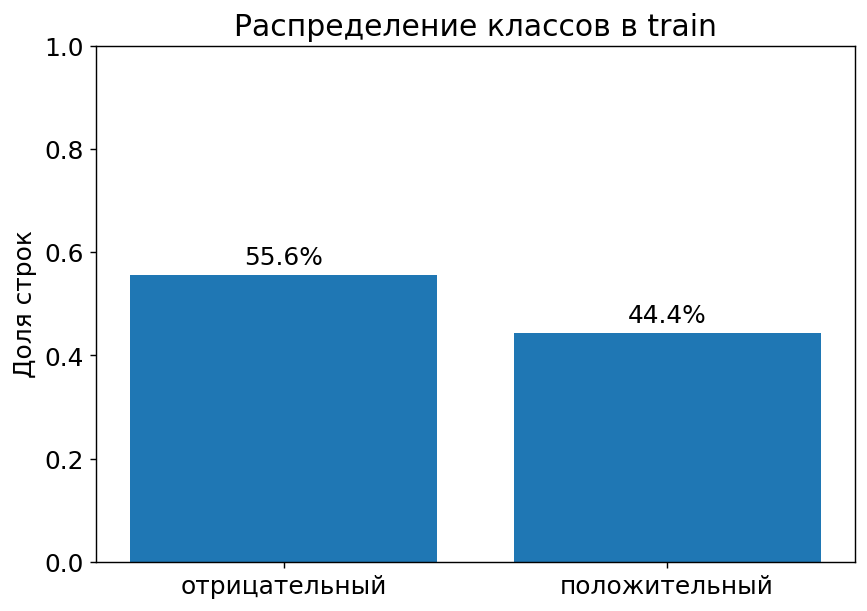

In [14]:
class_share = df_train[TARGET].value_counts(normalize=True).sort_index()

plt.figure()
plt.bar([0, 1], class_share.to_numpy())
plt.xticks([0, 1], ["отрицательный", "положительный"])
plt.ylim(0, 1)
plt.ylabel("Доля строк")
plt.title("Распределение классов в train")

for label, share in class_share.items():
    plt.text(label, share + 0.02, f"{share:.1%}", ha="center")

plt.tight_layout()
plt.show()

## Возраст, расстояние и задержки

Для непрерывных признаков посмотрим гистограммы. 

На двух графиках задержек вертикальная шкала логарифмическая, так как редкие ненулевые задержки почти не видны на фоне большого числа нулей. 

Распределение признака не обязано быть нормальным. Большое значение задержки само по себе ещё не доказывает ошибку, поэтому автоматически удалять хвост распределения не будем.

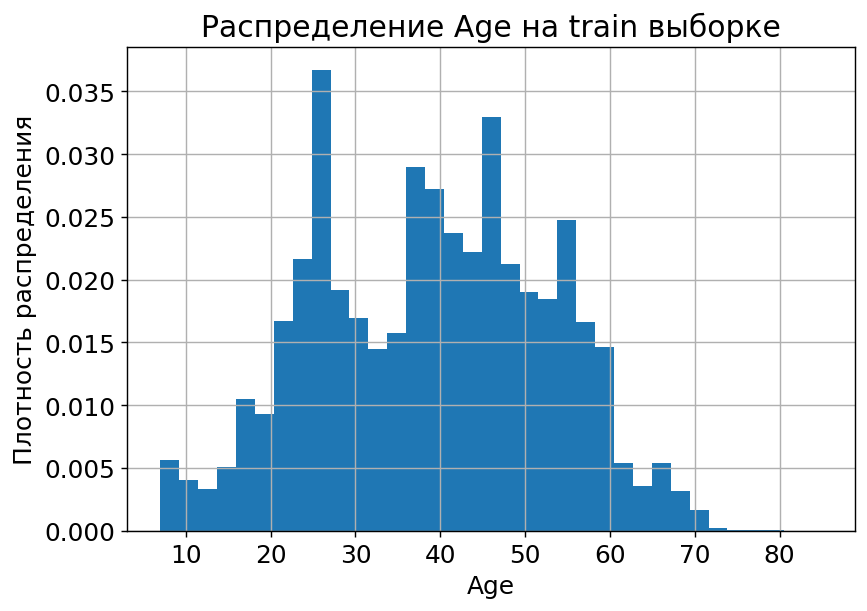

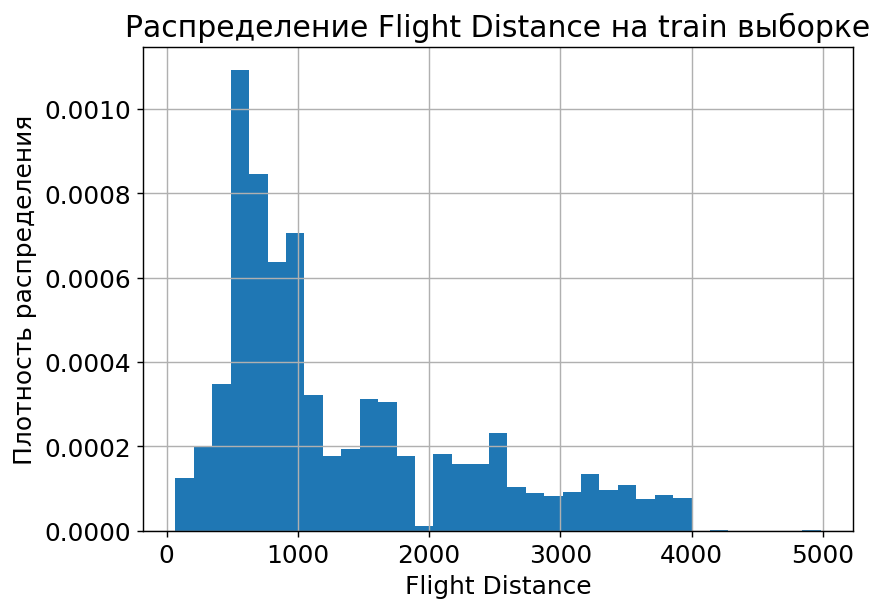

In [15]:
for column in ["Age", "Flight Distance"]:
    plt.figure()
    plt.hist(df_train[column].dropna(), bins=35, density=True)
    plt.title(f"Распределение {column} на train выборке")
    plt.xlabel(column)
    plt.ylabel("Плотность распределения")
    plt.tight_layout()
    plt.grid()
    plt.show()

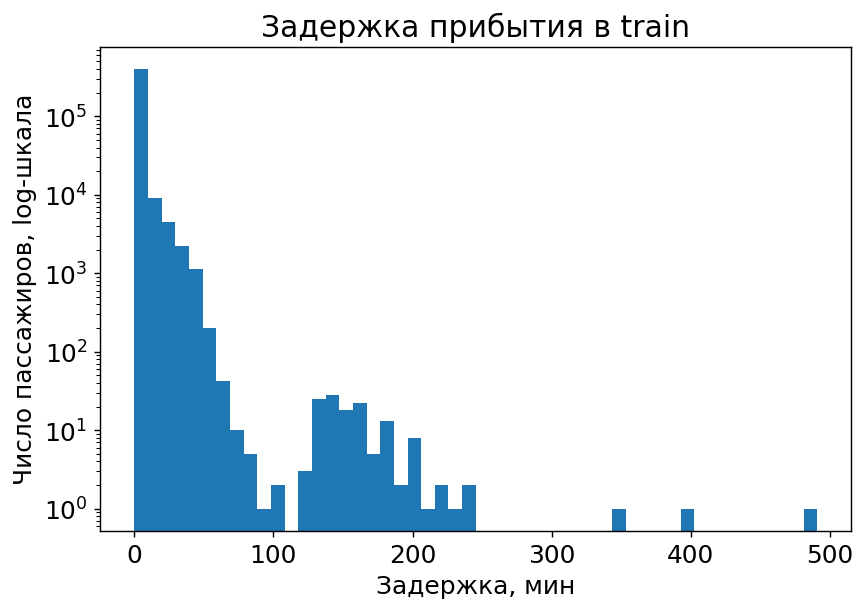

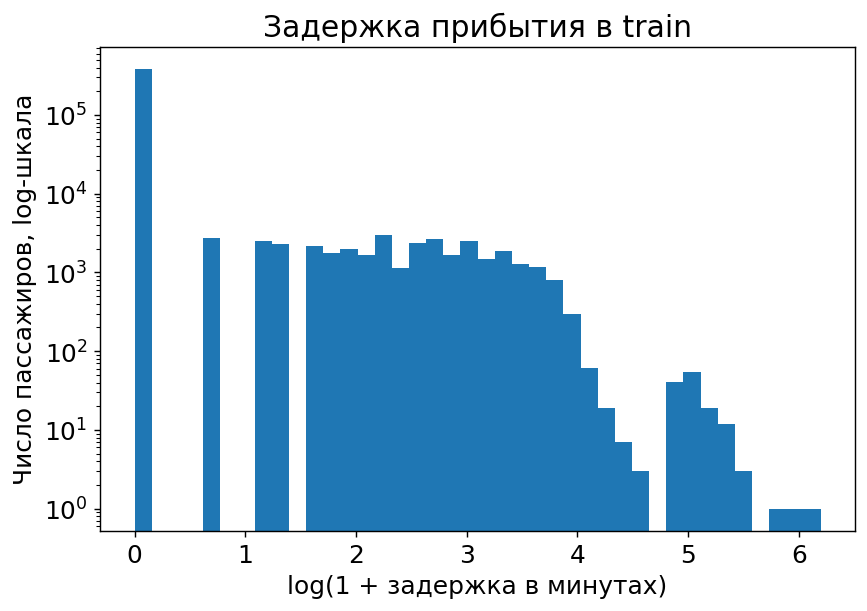

In [16]:
delay_column = "Arrival Delay in Minutes"
plt.figure()
plt.hist(df_train[delay_column].dropna(), bins=50)
plt.yscale("log")
plt.title("Задержка прибытия в train")
plt.xlabel("Задержка, мин")
plt.ylabel("Число пассажиров, log-шкала")
plt.tight_layout()
plt.show()

plt.figure()
plt.hist(np.log1p(df_train[delay_column].dropna()), bins=40)
plt.yscale("log")
plt.title("Задержка прибытия в train")
plt.xlabel("log(1 + задержка в минутах)")
plt.ylabel("Число пассажиров, log-шкала")
plt.tight_layout()
plt.show()

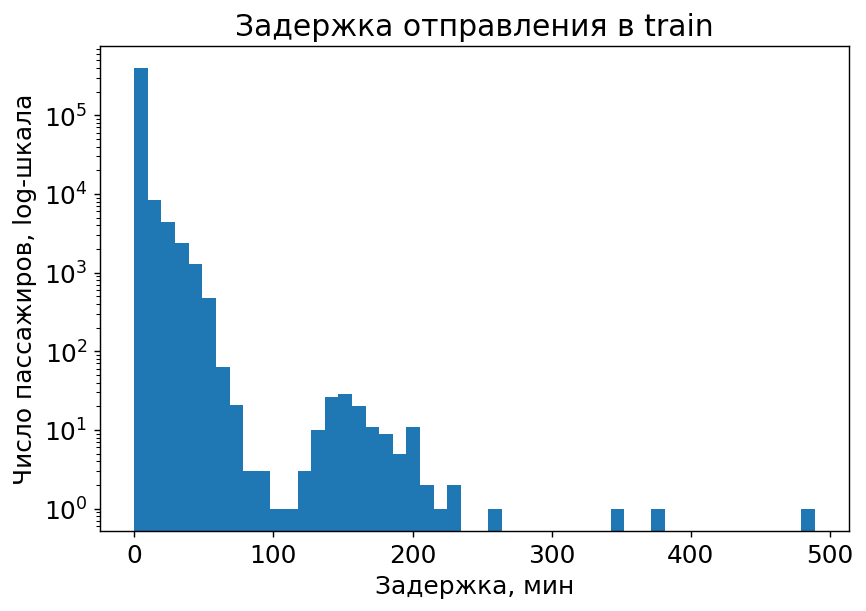

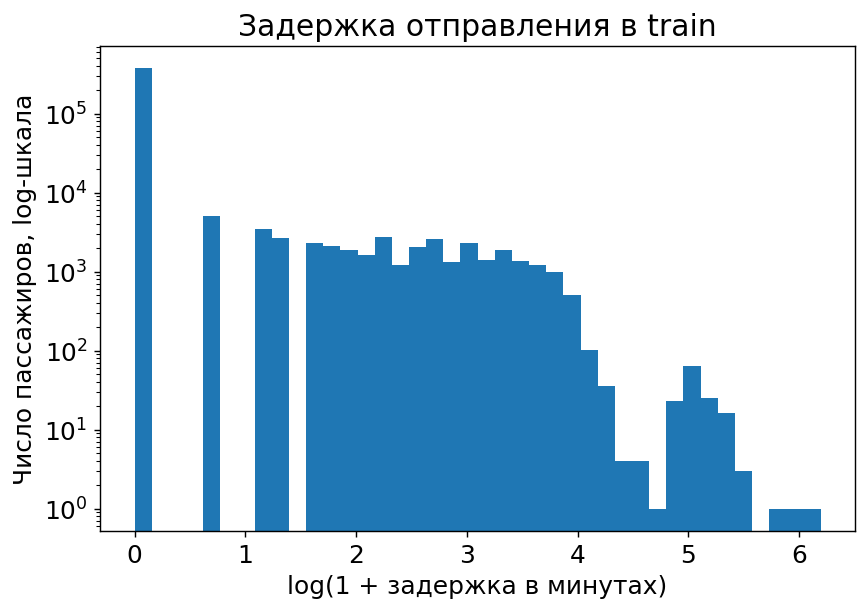

In [17]:
delay_column = "Departure Delay in Minutes"
plt.figure()
plt.hist(df_train[delay_column].dropna(), bins=50)
plt.yscale("log")
plt.title("Задержка отправления в train")
plt.xlabel("Задержка, мин")
plt.ylabel("Число пассажиров, log-шкала")
plt.tight_layout()
plt.show()

plt.figure()
plt.hist(np.log1p(df_train[delay_column].dropna()), bins=40)
plt.yscale("log")
plt.title("Задержка отправления в train")
plt.xlabel("log(1 + задержка в минутах)")
plt.ylabel("Число пассажиров, log-шкала")
plt.tight_layout()
plt.show()

Преобразование `log1p(x)` сжимает длинный правый хвост и определено при нулевой задержке. 

В предобработке применим логарифмирование к двум признакам задержки. 

## Категории и доля положительного класса

Сначала посмотрим размер каждой группы. Затем сравним частоту положительных ответов в классах обслуживания и типах поездок.

In [18]:
category_tables = []
for column in cols_cat:
    table = df_train.groupby(column, dropna=False)[TARGET].agg(["size", "mean"])
    table = table.rename(columns={"size": "Число строк", "mean": "Доля класса 1"})
    table.insert(0, "Признак", column)
    table.index.name = "Категория"
    category_tables.append(table.reset_index())
    
display(pd.concat(category_tables, ignore_index=True).round(4))

,Категория,Признак,Число строк,Доля класса 1
0,Female,Gender,208989,0.4384
1,Male,Gender,210792,0.4487
2,Loyal Customer,Customer Type,346231,0.4953
3,disloyal Customer,Customer Type,73550,0.2000
4,Business travel,Type of Travel,298577,0.5841
5,Personal Travel,Type of Travel,121204,0.0974
6,Business,Class,205558,0.7250
7,Eco,Class,196344,0.1671
8,Eco Plus,Class,17879,0.2434


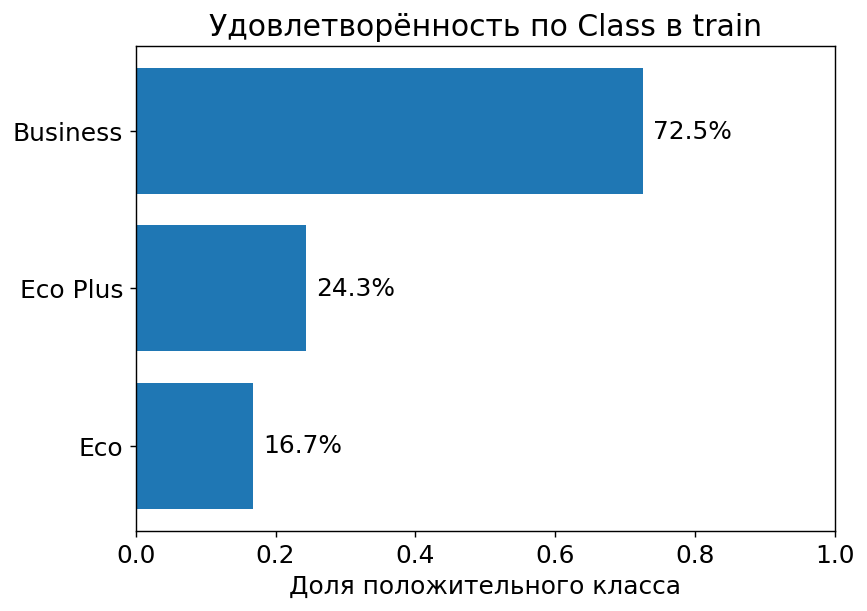

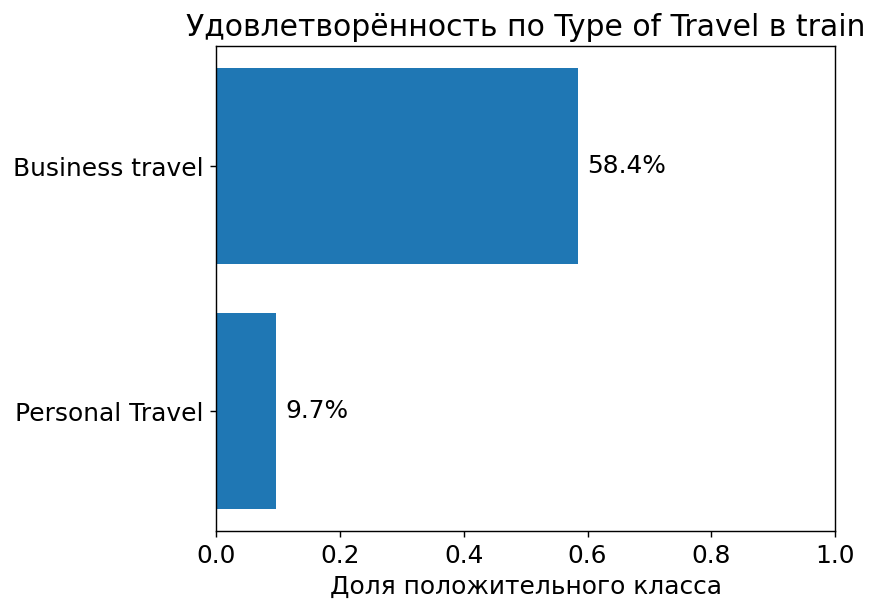

In [19]:
for column in ["Class", "Type of Travel"]:
    grouped = df_train.groupby(column)[TARGET].agg(["size", "mean"]).sort_values("mean")
    plt.figure()
    plt.barh(grouped.index.astype(str), grouped["mean"])
    plt.xlim(0, 1)
    plt.xlabel("Доля положительного класса")
    plt.title(f"Удовлетворённость по {column} в train")
    for i, row in enumerate(grouped.itertuples()):
        plt.text(min(row.mean + 0.015, 0.83), i, f"{row.mean:.1%}", va="center")
    plt.tight_layout()
    plt.show()

## Как связаны оценки сервиса с ответом

Одна числовая оценка не всегда связана с целевым классом линейно и даже монотонно. Учитываем также число наблюдений для каждого значения, так как доля по маленькой группе менее устойчива.

,Число строк,Доля класса 1
Inflight wifi service,,
0,7858,0.8867
1,64525,0.3896
2,111887,0.2701
3,110961,0.2770
4,76783,0.6224
5,47767,0.9494


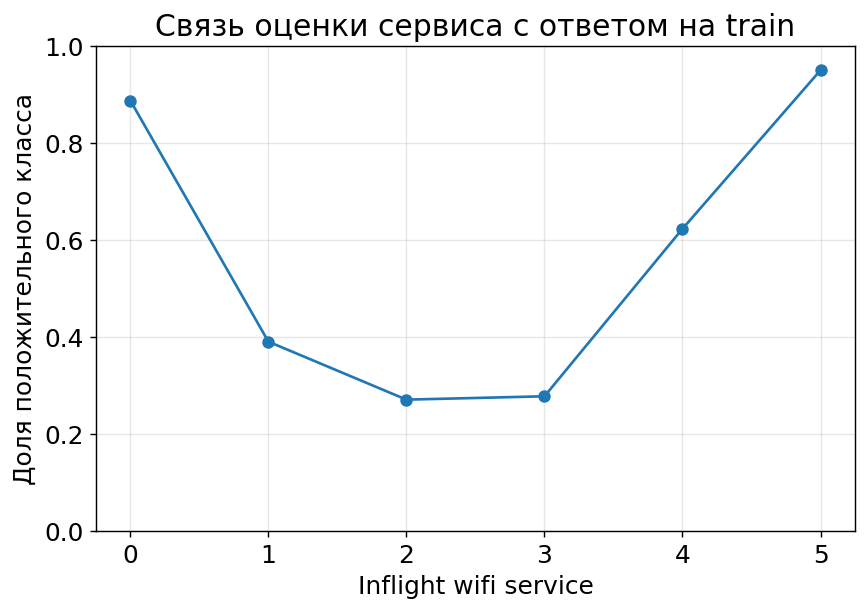

,Число строк,Доля класса 1
Online boarding,,
0,5465,0.6203
1,34570,0.1052
2,71434,0.0843
3,89974,0.1285
4,126619,0.6423
5,91719,0.8751


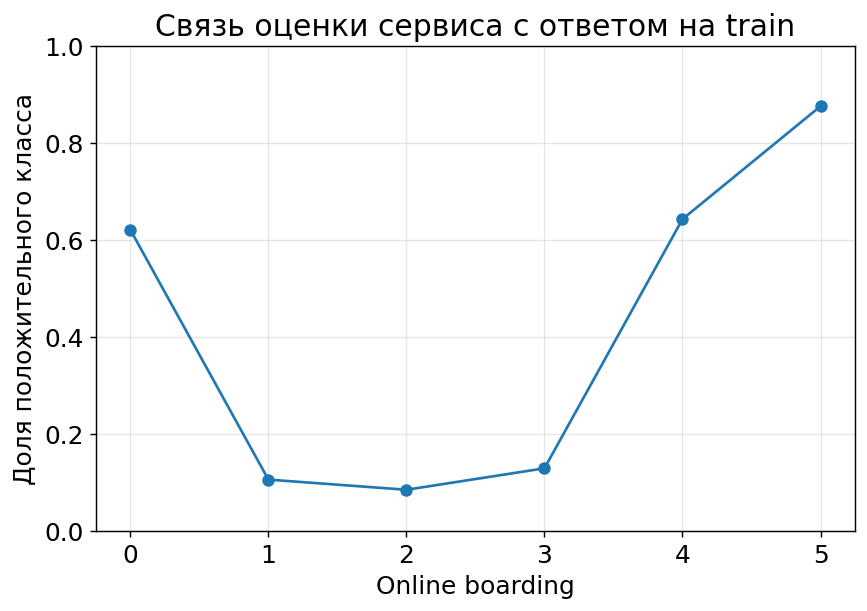

In [20]:
for column in ["Inflight wifi service", "Online boarding"]:
    grouped = df_train.groupby(column)[TARGET].agg(["size", "mean"]).sort_index()
    display(grouped.rename(columns={"size": "Число строк", "mean": "Доля класса 1"}).round(4))
    plt.figure()
    plt.plot(grouped.index, grouped["mean"], marker="o")
    plt.xticks(grouped.index)
    plt.ylim(0, 1)
    plt.xlabel(column)
    plt.ylabel("Доля положительного класса")
    plt.title("Связь оценки сервиса с ответом на train")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## Корреляции

Посчитаем корреляцию Спирмена числовых признаков с бинарным ответом. Она помогает увидеть монотонные связи. 

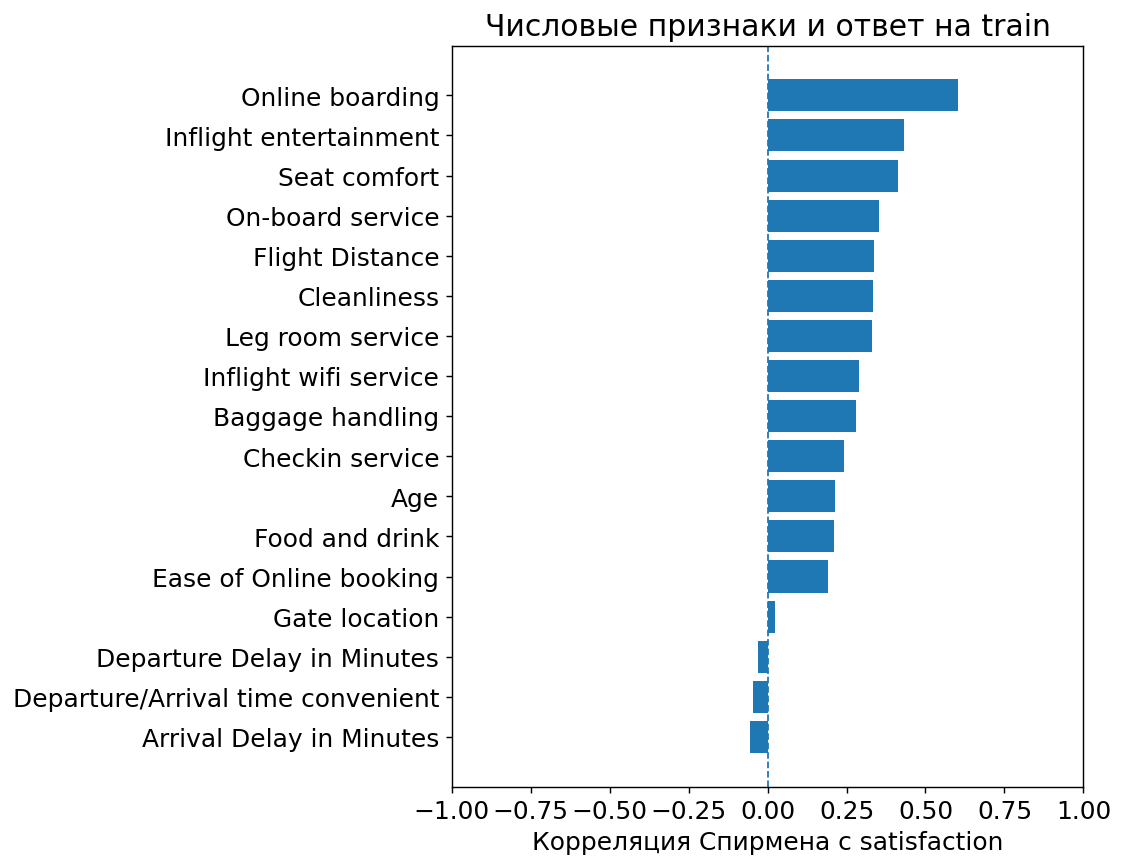

Корреляция двух задержек 0.841


In [21]:
corr_target = (
    df_train[cols_num + [TARGET]].corr(method="spearman")[TARGET]
    .drop(TARGET).sort_values()
)

plt.figure(figsize=(9, 7))
plt.barh(corr_target.index, corr_target.values)
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlim(-1, 1)
plt.xlabel("Корреляция Спирмена с satisfaction")
plt.title("Числовые признаки и ответ на train")
plt.tight_layout()
plt.show()
print("Корреляция двух задержек", round(df_train[["Departure Delay in Minutes", "Arrival Delay in Minutes"]].corr().iloc[0, 1], 4))

# Предобработка

Разделим два вида преобразований. 

- Создание индикатора пропуска и `log1p` выполняются по одной строке и не оценивают статистики набора.
- А медианы, средние, стандартные отклонения и словарь категорий нужно **обучить только на train**.

К валидации, отложенной выборке и тестовой выборке применяются уже найденные параметры.

Числовые пропуски заполним медианой. Затем стандартизируем числовые признаки по формуле $$x'=\frac{x-\mu_{train}}{s_{train}}$$. 

Категории закодируем по one-hot, где отделяется отдельная колонка-индикатор для каждой категории. 

`handle_unknown="ignore"` позволяет обработать новую категорию так, что все её индикаторы будут нулевыми, в качестве заглушки.

Такая последовательность предотвращает утечку информации из отложенных данных. Это относится даже к преобразованиям без целевых меток, например `StandardScaler`. См. [рекомендации sklearn об утечках](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [22]:
def make_features(frame):
    """Построчные преобразования: статистики выборки здесь не вычисляются."""
    result = frame.copy()
    result["arrival_delay_missing"] = result["Arrival Delay in Minutes"].isna().astype(float)
    rename_delays = {
        "Departure Delay in Minutes": "log_departure_delay",
        "Arrival Delay in Minutes": "log_arrival_delay",
    }
    for old_name, new_name in rename_delays.items():
        if (result[old_name].dropna() < 0).any():
            raise ValueError(f"Для log1p ожидается неотрицательная задержка: {old_name}")
        result[new_name] = np.log1p(result.pop(old_name))
    return result

X_train_raw = df_train[feature_columns]
X_val_raw = df_val[feature_columns]
y_train = df_train[TARGET].to_numpy()
y_val = df_val[TARGET].to_numpy()

X_train_features = make_features(X_train_raw)
X_val_features = make_features(X_val_raw)
numeric_features = [c for c in X_train_features.columns if c not in cols_cat]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
category_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", category_pipeline, cols_cat),
], remainder="drop", verbose_feature_names_out=False)

X_train = np.ascontiguousarray(preprocessor.fit_transform(X_train_features), dtype=np.float64)
X_val = np.ascontiguousarray(preprocessor.transform(X_val_features), dtype=np.float64)
feature_names = preprocessor.get_feature_names_out()
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
assert X_train.shape[1] == X_val.shape[1]
print("До кодирования", X_train_raw.shape, "и после", X_train.shape)
display(pd.DataFrame(X_train[:5], columns=feature_names).round(3))

До кодирования (419781, 21) и после (419781, 27)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,arrival_delay_missing,log_departure_delay,log_arrival_delay,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
0,-0.145,-1.210,0.952,0.571,1.643,1.582,0.565,1.269,0.337,0.417,-0.418,-1.160,-0.747,0.477,0.484,-0.02,-0.290,-0.282,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1,1.160,0.460,0.172,-0.108,-0.612,-0.013,1.334,1.269,0.337,-1.113,-1.225,-1.160,-1.674,1.303,0.484,-0.02,-0.290,-0.282,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2,0.580,0.175,0.952,0.571,0.891,0.785,-0.205,0.493,0.337,1.182,1.197,1.200,1.107,0.477,1.267,-0.02,-0.290,-0.282,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0.725,-0.519,0.952,1.249,1.643,1.582,0.565,0.493,0.337,0.417,-2.033,-1.947,-1.674,-1.175,0.484,-0.02,-0.290,-0.282,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.580,-0.375,0.952,0.571,0.891,0.785,-0.205,1.269,1.122,1.182,1.197,1.200,1.107,1.303,0.484,-0.02,4.351,4.072,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


In [23]:
# Словарь категорий и пример one-hot-кодирования.
encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]
display(pd.Series({name: list(values) for name, values in zip(cols_cat, encoder.categories_)}, name="Категории train"))

Gender                                 [Female, Male]
Customer Type     [Loyal Customer, disloyal Customer]
Type of Travel     [Business travel, Personal Travel]
Class                       [Business, Eco, Eco Plus]
Name: Категории train, dtype: object

In [24]:
onehot_preview = pd.DataFrame(
    X_train[:5, len(numeric_features):],
    columns=feature_names[len(numeric_features):],
    index=X_train_raw.index[:5],
)

display(pd.concat([X_train_raw[cols_cat].head(), onehot_preview], axis=1))

,Gender,Customer Type,Type of Travel,Class,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
358271,Male,Loyal Customer,Business travel,Eco,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
234202,Male,Loyal Customer,Business travel,Business,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
545044,Male,Loyal Customer,Business travel,Business,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3171,Male,Loyal Customer,Business travel,Eco,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
241792,Male,Loyal Customer,Business travel,Business,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


# Метрики качества решения задачи

**ROC-AUC** оценивает ранжирование, насколько часто положительный объект получает больший балл, чем отрицательный. 

Для расчёта подаём непрерывные вероятности, а не готовые классы. Дополнительно посчитаем **Average Precision (AP)** — показатель ранжирования по precision–recall.

Для вероятностей нужны **log loss** и **Brier score** — средняя квадратичная ошибка между вероятностью и бинарным исходом. 

Чем они меньше, тем лучше. Они оценивают вероятностный прогноз в целом, а не исключительно калибровку. Для калибровки дополнительно построим отдельную диаграмму.

**Accuracy, precision, recall и F1** вычисляются после выбора порога классификации. По умолчанию берём 0.5.

In [25]:
def evaluate_probabilities(y_true, probabilities, threshold=0.5):
    y_true = np.asarray(y_true).ravel()
    probabilities = np.asarray(probabilities, dtype=float).ravel()
    if len(y_true) != len(probabilities) or not np.isfinite(probabilities).all():
        raise ValueError("Неверная длина или нечисловые вероятности.")
    if np.any((probabilities < 0) | (probabilities > 1)):
        raise ValueError("Вероятности должны лежать в [0, 1].")
    labels = (probabilities >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "AP": average_precision_score(y_true, probabilities),
        "Log loss": log_loss(y_true, probabilities, labels=[0, 1]),
        "Brier": brier_score_loss(y_true, probabilities),
        "Accuracy": accuracy_score(y_true, labels),
        "Precision": precision_score(y_true, labels, zero_division=0),
        "Recall": recall_score(y_true, labels, zero_division=0),
        "F1": f1_score(y_true, labels, zero_division=0),
    }

models, fit_times, validation_probabilities = {}, {}, {}

start = perf_counter()
dummy_model = DummyClassifier(strategy="prior").fit(X_train, y_train)
fit_times["Dummy: доля класса"] = perf_counter() - start
models["Dummy: доля класса"] = dummy_model
p_dummy = dummy_model.predict_proba(X_val)[:, 1]
validation_probabilities["Dummy: доля класса"] = p_dummy
display(pd.Series(evaluate_probabilities(y_val, p_dummy), name="Validation: постоянная вероятность").round(4))

ROC-AUC      0.5000
AP           0.4436
Log loss     0.6868
Brier        0.2468
Accuracy     0.5564
Precision    0.0000
Recall       0.0000
F1           0.0000
Name: Validation: постоянная вероятность, dtype: float64

Постоянная вероятность равна доле положительного класса в обучении. Она не ранжирует пассажиров и даёт ROC-AUC = 0.5.

# Собственная сигмоидальная регрессия

Сначала получим линейный ответ $z_i=w_0 \cdot 1 + x_i^T w$, где $w = (w_1, w_2, \dots, w_m)$ — веса признаков, а $w_0$ — свободный коэффициент. Пропустим его через сигмоиду:

$$p_i=\sigma(z_i)=\frac{1}{1+e^{-z_i}}.$$

Это оценка вероятности положительного класса. 

При пороге $t$ решение имеет вид $\hat y_i=\mathbb{1}[p_i\ge t]$. При $t=0.5$ граница соответствует $z=0$. 

Сигмоида ограничивает ответ диапазоном от 0 до 1, но **сама по себе не гарантирует правильность вероятностей**.

Логарифм отношения шансов линейно зависит от признаков $\log(p/(1-p))=w_0+x^Tw$. Именно эта форма с log loss называется логистической регрессией.

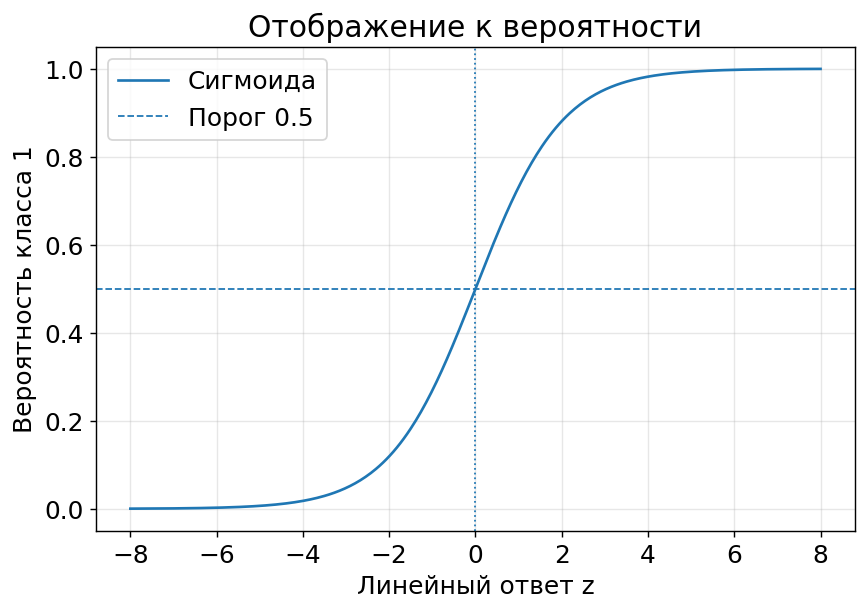

In [26]:
def sigmoid(z):
    z = np.asarray(z, dtype=np.float64)
    result = np.empty_like(z)
    positive = z >= 0
    result[positive] = 1.0 / (1.0 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1.0 + exp_z)
    return result

z = np.linspace(-8, 8, 400)
plt.figure()
plt.plot(z, sigmoid(z), label="Сигмоида")
plt.axhline(0.5, linestyle="--", linewidth=1, label="Порог 0.5")
plt.axvline(0, linestyle=":", linewidth=1)
plt.xlabel("Линейный ответ z")
plt.ylabel("Вероятность класса 1")
plt.title("Отображение к вероятности")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
pd.DataFrame(
    {
        "z": [-1000, -2, 0, 2, 1000], 
        "sigmoid": sigmoid([-1000, -2, 0, 2, 1000])
    }
)

,z,sigmoid
0,-1000,0.000000
1,-2,0.119203
2,0,0.500000
3,2,0.880797
4,1000,1.000000


## Почему можно учиться по нулям и единицам?

Обозначим истинную, но неизвестную вероятность через $\eta(x)=P(Y=1\mid X=x)$. Для фиксированного $x$ средняя квадратичная ошибка предсказания $p$ равна

$$\mathbb E[(Y-p)^2\mid X=x]=\eta(x)(1-p)^2+(1-\eta(x))p^2
=(p-\eta(x))^2+\eta(x)(1-\eta(x)).$$

Второе слагаемое не зависит от $p$, поэтому минимум достигается при $p=\eta(x)$. Так бинарные наблюдения позволяют оценивать вероятность. Но на конечной выборке результат ограничен объёмом данных, выбранной моделью и качеством оптимизации. У одного пассажира мы видим один исход, а не его «истинную вероятность».

В первом исходном блокноте сигмоида обучалась с MSE. Сохраним этот вариант и сравним его с бинарной кросс-энтропией, она же log loss:

$$L_{MSE}=\frac1n\sum_i(p_i-y_i)^2,$$
$$L_{BCE}=-\frac1n\sum_i\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right].$$

Для обеих функций популяционный минимум по свободному $p$ совпадает с $\eta(x)$. Но MSE после сигмоиды в общем случае не является выпуклой по весам, и её градиент затухает в насыщении. BCE для линейного логита выпукла по параметрам. Поэтому одинаковая сигмоида ещё не означает одинаковое обучение.

## Градиент функции потерь

Добавим к матрице признаков столбец единиц и обозначим $A=[\mathbf 1,X]$, $\theta=[b,w]^T$. Тогда $p=\sigma(A\theta)$, а градиенты имеют вид

$$\nabla_\theta L_{MSE}=\frac{2}{n}A^T\big[(p-y)\odot p\odot(1-p)\big],$$
$$\nabla_\theta L_{BCE}=\frac{1}{n}A^T(p-y).$$

Знак $\odot$ означает поэлементное произведение. Множитель 2 в MSE соответствует именно $\operatorname{mean}(p-y)^2$, а не половине этого выражения.

Добавим регуляризацию $\frac\lambda2\|w\|_2^2$. Она штрафует большие веса, но не свободный коэффициент. Её вклад в градиент равен $\lambda[0,w]^T$. Шаг обучения: $\theta\leftarrow\theta-\alpha\nabla_\theta L$.

Для численной устойчивости BCE вычислим через логиты как $\ell(z,y)=\log(1+e^z)-yz$. Функция `np.logaddexp(0, z)` вычисляет первый член без прямого переполнения экспоненты.

In [28]:
def data_loss(y, logits, loss="bce"):
    if loss == "mse":
        return float(np.mean((sigmoid(logits) - y) ** 2))
    else:
        return float(np.mean(np.logaddexp(0.0, logits) - y * logits))


def loss_and_gradient(A, y, theta, loss="bce", l2=0.0):
    logits = A @ theta
    probabilities = sigmoid(logits)
    error = probabilities - y
    if loss == "mse":
        error = 2.0 * error * probabilities * (1.0 - probabilities)

    gradient = A.T @ error / len(y)
    gradient[1:] += l2 * theta[1:]
    objective = data_loss(y, logits, loss) + 0.5 * l2 * np.dot(theta[1:], theta[1:])
    return objective, gradient

## Проверяем производные

Перед обучением сравним аналитический градиент с центральной конечной разностью на маленькой матрице. Такой тест обнаруживает ошибки знака, пропущенный множитель и неправильную регуляризацию свободного коэффициента. Он проверяет код производной, а не качество будущего классификатора.

In [29]:
rng = np.random.default_rng(SEED)
A_check = np.column_stack([np.ones(11), rng.normal(size=(11, 4))])
y_check = rng.integers(0, 2, size=11).astype(float)
theta_check = rng.normal(scale=0.2, size=A_check.shape[1])
epsilon = 1e-6

gradient_checks = []
for loss_name in ["mse", "bce"]:
    _, analytical = loss_and_gradient(A_check, y_check, theta_check, loss_name, l2=0.07)
    numerical = np.zeros_like(theta_check)
    for j in range(len(theta_check)):
        shift = np.zeros_like(theta_check)
        shift[j] = epsilon
        plus = loss_and_gradient(A_check, y_check, theta_check + shift, loss_name, 0.07)[0]
        minus = loss_and_gradient(A_check, y_check, theta_check - shift, loss_name, 0.07)[0]
        numerical[j] = (plus - minus) / (2 * epsilon)
    error = np.max(np.abs(analytical - numerical))
    gradient_checks.append({"Потери": loss_name, "Максимальная ошибка градиента": error})
    np.testing.assert_allclose(analytical, numerical, atol=1e-7, rtol=1e-5)

assert np.isfinite(sigmoid([-1000, 1000])).all()
assert np.isfinite(data_loss(np.array([1, 0]), np.array([-1000, 1000]), "bce"))
display(pd.DataFrame(gradient_checks))
print("Проверки градиентов и численной устойчивости пройдены.")

,Потери,Максимальная ошибка градиента
0,mse,2.086794e-11
1,bce,1.035724e-10


Проверки градиентов и численной устойчивости пройдены.


## Реализуем класс модели

Вычисления ответа, потерь, градиента и обновления весов выполняет код NumPy. 

От `sklearn` берём только проверку входов и стандартный интерфейс, чтобы модель можно было клонировать и включать в `Pipeline`.

За эпоху проходим всю обучающую выборку небольшими пакетами — мини-батчами. Перед каждой эпохой переставляем индексы строк. Для обычного градиентного спуска необходимо поставить `batch_size=None`.

- `predict_proba` возвращает два столбца, $P(Y=0)$ и $P(Y=1)$. 
- `predict` возвращает классы. 

Валидационные потери только записываем для визуализации, и не используем для обновления весов или ранней остановки. Число эпох фиксируем заранее.

In [30]:
class SigmoidRegression(ClassifierMixin, BaseEstimator):
    def __init__(self, loss="bce", learning_rate=0.15, n_epochs=120,
                 batch_size=8192, l2=1e-4, random_state=42, record_every=5):
        self.loss = loss
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.l2 = l2
        self.random_state = random_state
        self.record_every = record_every

    def fit(self, X, y, X_val=None, y_val=None):
        X, y = check_X_y(X, y, dtype=np.float64)
        if not np.array_equal(np.unique(y), [0, 1]):
            raise ValueError("Ожидаются оба класса, закодированные как 0 и 1.")
        if self.learning_rate <= 0 or self.l2 < 0:
            raise ValueError("learning_rate > 0, l2 >= 0.")
        if not isinstance(self.n_epochs, (int, np.integer)) or self.n_epochs < 1:
            raise ValueError("n_epochs — положительное целое число.")
        if not isinstance(self.record_every, (int, np.integer)) or self.record_every < 1:
            raise ValueError("record_every — положительное целое число.")
        if self.batch_size is not None and (
            not isinstance(self.batch_size, (int, np.integer)) or self.batch_size < 1
        ):
            raise ValueError("batch_size — положительное целое число или None.")
        if (X_val is None) != (y_val is None):
            raise ValueError("X_val и y_val нужно передавать вместе.")

        self.n_features_in_ = X.shape[1]
        self.classes_ = np.array([0, 1])
        y = y.astype(np.float64)
        A = np.column_stack([np.ones(len(X)), X])
        rng = np.random.default_rng(self.random_state)
        theta = rng.normal(scale=0.01, size=A.shape[1])
        prior = np.clip(y.mean(), 1e-6, 1 - 1e-6)
        theta[0] = np.log(prior / (1 - prior))
        batch_size = len(y) if self.batch_size is None else min(self.batch_size, len(y))

        A_val = None
        if X_val is not None:
            X_val, y_val = check_X_y(X_val, y_val, dtype=np.float64)
            if X_val.shape[1] != self.n_features_in_ or not np.isin(y_val, [0, 1]).all():
                raise ValueError("Несовместимые признаки или метки validation.")
            A_val = np.column_stack([np.ones(len(X_val)), X_val])

        self.history_ = []
        for epoch in range(self.n_epochs + 1):
            if epoch > 0:
                order = rng.permutation(len(y))
                for start in range(0, len(y), batch_size):
                    indices = order[start:start + batch_size]
                    _, gradient = loss_and_gradient(
                        A[indices], y[indices], theta, self.loss, self.l2
                    )
                    theta -= self.learning_rate * gradient

            if epoch % self.record_every == 0 or epoch == self.n_epochs:
                train_loss = data_loss(y, A @ theta, self.loss)
                if not np.isfinite(train_loss) or not np.isfinite(theta).all():
                    raise FloatingPointError("Обучение расходится. Уменьшите learning_rate.")
                self.history_.append({
                    "epoch": epoch,
                    "train_loss": train_loss,
                    "val_loss": data_loss(y_val, A_val @ theta, self.loss) if A_val is not None else np.nan,
                })

        self.theta_ = theta.copy()
        self.coef_ = theta[1:].reshape(1, -1)
        self.intercept_ = theta[:1].copy()
        self.n_iter_ = self.n_epochs
        return self

    def decision_function(self, X):
        check_is_fitted(self, "theta_")
        X = check_array(X, dtype=np.float64)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от обучающей матрицы.")
        return X @ self.theta_[1:] + self.theta_[0]

    def predict_proba(self, X):
        p = sigmoid(self.decision_function(X))
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        if not 0 <= threshold <= 1:
            raise ValueError("Порог должен лежать в [0, 1].")
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

## Небольшой пример с известной вероятностью

Только в этой ячейке создадим искусственную задачу. Зададим истинную сигмоиду и случайно получим бинарные ответы из распределения Бернулли. Модель увидит только точки с метками 0 и 1, но должна восстановить близкую вероятностную кривую.

У данных Kaggle истинная вероятность отдельного объекта неизвестна. Поэтому такой график сравнения с «истинной кривой» нельзя честно построить для пассажиров из соревнования.

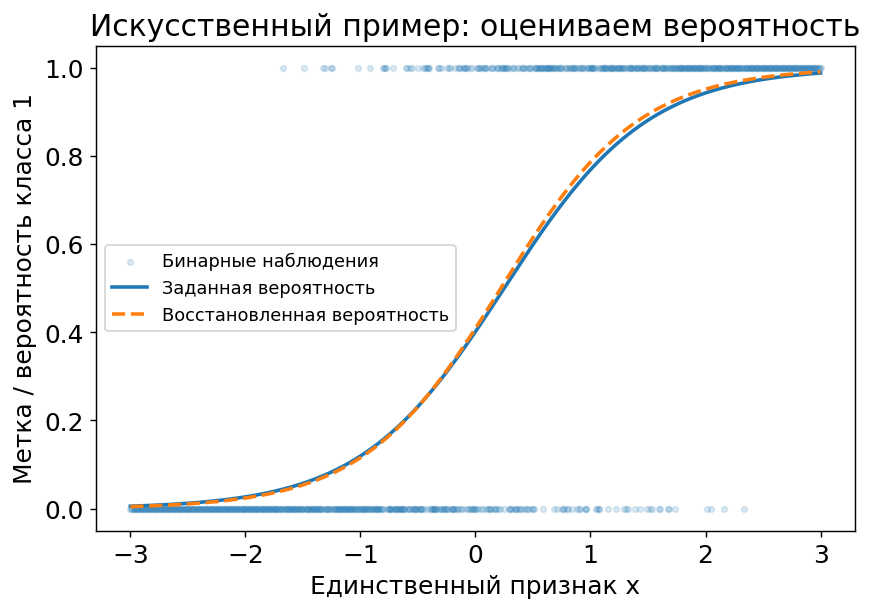

Истинные b, w: -0.4, 1.6
Оценённые b, w: [-0.3683  1.6686]


In [31]:
toy_rng = np.random.default_rng(SEED)
toy_x = np.linspace(-3, 3, 800).reshape(-1, 1)
toy_true_probability = sigmoid(1.6 * toy_x[:, 0] - 0.4)
toy_y = toy_rng.binomial(1, toy_true_probability)
toy_model = SigmoidRegression(
    loss="bce", learning_rate=0.2, n_epochs=500, batch_size=None,
    l2=0.0, random_state=SEED,
).fit(toy_x, toy_y)
toy_prediction = toy_model.predict_proba(toy_x)[:, 1]

plt.figure()
plt.scatter(toy_x[:, 0], toy_y, s=10, alpha=0.15, label="Бинарные наблюдения")
plt.plot(toy_x[:, 0], toy_true_probability, linewidth=2, label="Заданная вероятность")
plt.plot(toy_x[:, 0], toy_prediction, linestyle="--", linewidth=2, label="Восстановленная вероятность")
plt.xlabel("Единственный признак x")
plt.ylabel("Метка / вероятность класса 1")
plt.title("Искусственный пример: оцениваем вероятность")
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()
print("Истинные b, w: -0.4, 1.6")
print("Оценённые b, w:", np.round(toy_model.theta_, 4))

# Обучение на данных пассажиров

In [32]:
model_mse = SigmoidRegression(
    loss="mse", learning_rate=0.4, n_epochs=EPOCHS, batch_size=BATCH_SIZE,
    l2=L2, random_state=SEED,
)

start = perf_counter()
model_mse.fit(X_train, y_train, X_val=X_val, y_val=y_val)
fit_times["Своя сигмоида MSE"] = perf_counter() - start
models["Своя сигмоида MSE"] = model_mse
validation_probabilities["Своя сигмоида MSE"] = model_mse.predict_proba(X_val)[:, 1]

pd.Series(
    evaluate_probabilities(y_val, validation_probabilities["Своя сигмоида MSE"]), 
    name="Validation MSE").round(4)

ROC-AUC      0.9227
AP           0.9114
Log loss     0.3657
Brier        0.0936
Accuracy     0.8833
Precision    0.8859
Recall       0.8459
F1           0.8655
Name: Validation MSE, dtype: float64

In [33]:
model_bce = SigmoidRegression(
    loss="bce", learning_rate=0.15, n_epochs=EPOCHS, batch_size=BATCH_SIZE,
    l2=L2, random_state=SEED,
)
start = perf_counter()
model_bce.fit(X_train, y_train, X_val=X_val, y_val=y_val)
fit_times["Своя сигмоида BCE"] = perf_counter() - start
models["Своя сигмоида BCE"] = model_bce
validation_probabilities["Своя сигмоида BCE"] = model_bce.predict_proba(X_val)[:, 1]

pd.Series(
    evaluate_probabilities(y_val, validation_probabilities["Своя сигмоида BCE"]), 
    name="Validation BCE").round(4)

ROC-AUC      0.9220
AP           0.9093
Log loss     0.3432
Brier        0.0969
Accuracy     0.8791
Precision    0.8758
Recall       0.8476
F1           0.8615
Name: Validation BCE, dtype: float64

## Кривые обучения

На каждой диаграмме сравниваем train и validation для одной функции потерь. 

В графики не включён штраф регуляризации. Обе линии показывают именно ошибку прогноза на соответствующих строках.

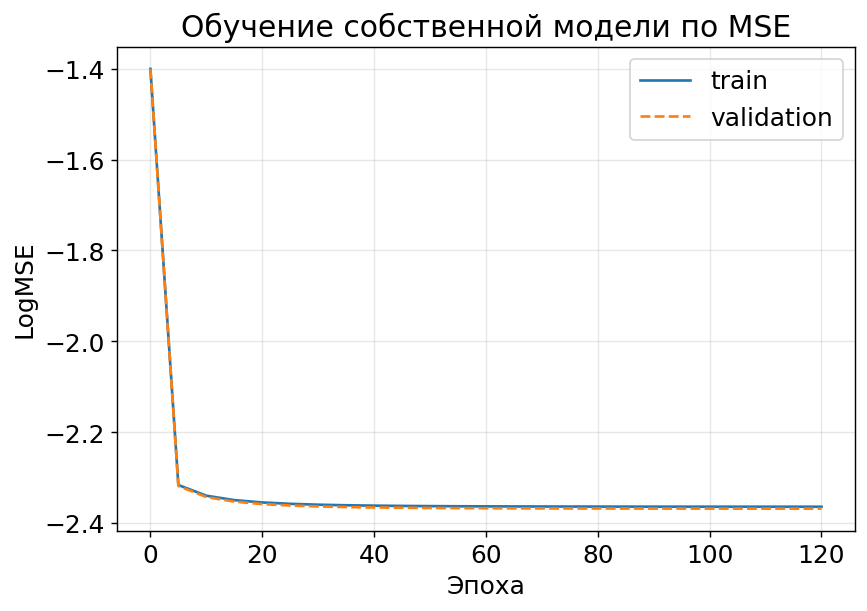

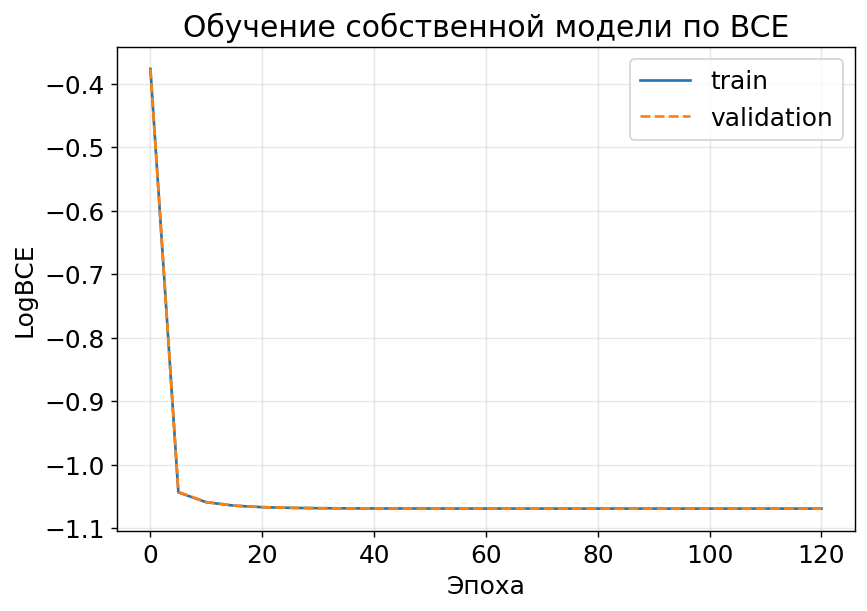

In [34]:
for name, model in [("MSE", model_mse), ("BCE", model_bce)]:
    history = pd.DataFrame(model.history_)
    plt.figure()
    plt.plot(history["epoch"], np.log(history["train_loss"]), label="train")
    plt.plot(history["epoch"], np.log(history["val_loss"]), linestyle="--", label="validation")
    plt.xlabel("Эпоха")
    plt.ylabel("Log" + name)
    plt.title(f"Обучение собственной модели по {name}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

np.testing.assert_allclose(model_bce.predict_proba(X_val[:10]).sum(axis=1), 1.0)

# Сравнение с моделями sklearn

Начнём с `LogisticRegression`, чтобы сравнить собственный градиентный спуск с библиотечным решателем. 

Затем рассмотрим наивный байесовский классификатор, дерево, случайный лес и гистограммный градиентный бустинг. 

Все модели получают одинаковые подготовленные признаки и одну обучающую часть.

Гиперпараметры фиксируем заранее. 

## Cопоставим регуляризацию

В нашей BCE-модели минимизируется средний log loss плюс $\lambda\|w\|^2/2$. Для `LogisticRegression` без весов наблюдений соответствующий коэффициент при штрафе равен $1/(nC)$, поэтому берём

$$C=\frac{1}{n\lambda}.$$

При таком выборе сравниваем одну и ту же целевую функцию. 

В sklearn для обучения используется `lbfgs`, а мы используем мини-батчевый спуск. Они могут дать разные ответы из-за критериев остановки и конечного числа шагов. 

In [35]:
C_equivalent = 1.0 / (len(y_train) * L2)
sklearn_candidates = {
    "LogisticRegression": LogisticRegression(
        C=C_equivalent, max_iter=1500, tol=1e-8
    ),
    "GaussianNB": GaussianNB(),
    "DecisionTree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=50, random_state=SEED
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=160, max_depth=14, min_samples_leaf=10,
        n_jobs=N_JOBS, random_state=SEED,
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=220, learning_rate=0.08, max_leaf_nodes=31,
        min_samples_leaf=30, l2_regularization=1.0,
        early_stopping=False, random_state=SEED,
    ),
}

for name, model in sklearn_candidates.items():
    start = perf_counter()
    model.fit(X_train, y_train)
    fit_times[name] = perf_counter() - start
    assert np.array_equal(model.classes_, [0, 1])
    models[name] = model
    validation_probabilities[name] = model.predict_proba(X_val)[:, 1]
    print(f"{name}: fit = {fit_times[name]:.2f} с")

LogisticRegression: fit = 3.66 с
GaussianNB: fit = 0.28 с
DecisionTree: fit = 2.65 с
RandomForest: fit = 48.87 с
HistGradientBoosting: fit = 13.07 с


In [36]:
# Сравниваем именно BCE-цели
lr = models["LogisticRegression"]
A_train = np.column_stack([np.ones(len(X_train)), X_train])
theta_lr = np.r_[lr.intercept_[0], lr.coef_[0]]
objective_comparison = pd.DataFrame({
    "BCE L2 на train": [
        loss_and_gradient(A_train, y_train, model_bce.theta_, "bce", L2)[0],
        loss_and_gradient(A_train, y_train, theta_lr, "bce", L2)[0],
    ],
}, index=["mini-batch GD", "sklearn L-BFGS"])
display(objective_comparison.round(6))
print("Средняя разница вероятностей на validation:", round(np.mean(np.abs(
    validation_probabilities["Своя сигмоида BCE"] - validation_probabilities["LogisticRegression"]
)), 6))
del A_train

,BCE L2 на train
mini-batch GD,0.343555
sklearn L-BFGS,0.343528


Средняя разница вероятностей на validation: 0.000805


## Общая таблица результатов

Основная сортировка — по ROC-AUC на validation. 

In [37]:
comparison_rows = []
for name, model in models.items():
    row = {"Модель": name, **evaluate_probabilities(y_val, validation_probabilities[name])}
    row["Train AUC"] = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    row["Fit, с"] = fit_times[name]
    comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows).set_index("Модель").sort_values(
    ["ROC-AUC", "Log loss"], ascending=[False, True]
)

display(comparison.round(4))

comparison.to_csv("validation_metrics.csv", encoding="utf-8-sig")

,ROC-AUC,AP,Log loss,Brier,Accuracy,Precision,Recall,F1,Train AUC,"Fit, с"
Модель,,,,,,,,,,
HistGradientBoosting,0.9585,0.9428,0.2276,0.0608,0.9255,0.9264,0.9038,0.9150,0.9616,13.0687
RandomForest,0.9564,0.9405,0.2360,0.0633,0.9229,0.9202,0.9047,0.9124,0.9639,48.8691
DecisionTree,0.9501,0.9281,0.2576,0.0710,0.9112,0.9157,0.8808,0.8979,0.9513,2.6473
Своя сигмоида MSE,0.9227,0.9114,0.3657,0.0936,0.8833,0.8859,0.8459,0.8655,0.9227,14.3543
Своя сигмоида BCE,0.9220,0.9093,0.3432,0.0969,0.8791,0.8758,0.8476,0.8615,0.9221,13.0272
LogisticRegression,0.9220,0.9093,0.3432,0.0969,0.8790,0.8752,0.8482,0.8615,0.9221,3.6553
GaussianNB,0.9079,0.8945,1.3105,0.1368,0.8513,0.8383,0.8236,0.8309,0.9075,0.2757
Dummy: доля класса,0.5000,0.4436,0.6868,0.2468,0.5564,0.0000,0.0000,0.0000,0.5000,0.0106


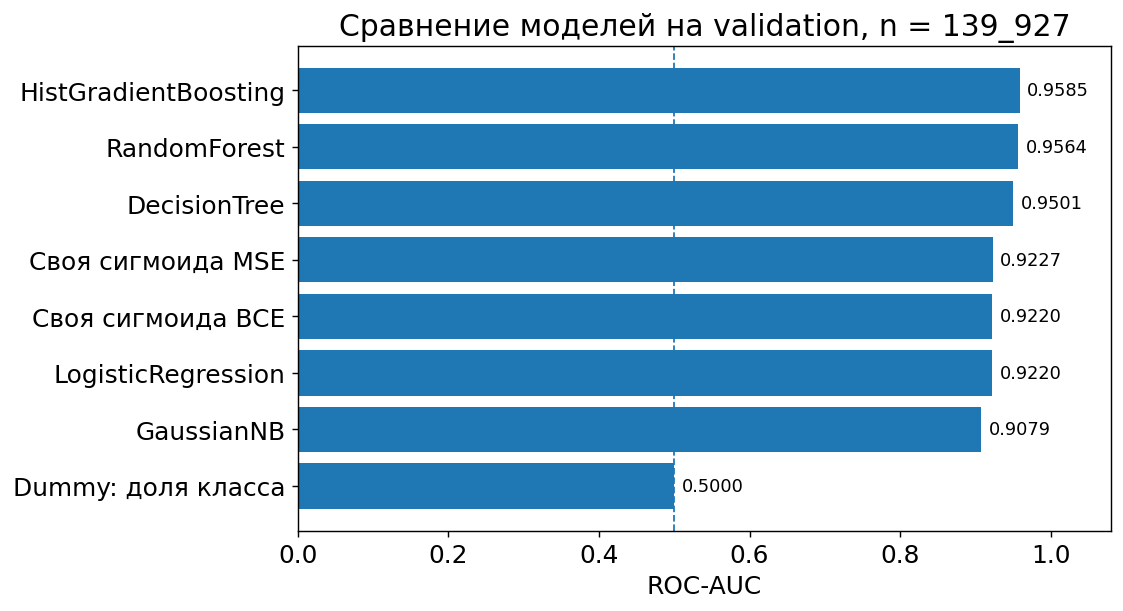

In [38]:
plot_table = comparison["ROC-AUC"].sort_values()
plt.figure(figsize=(9, 5))
plt.barh(plot_table.index, plot_table.values)
plt.axvline(0.5, linestyle="--", linewidth=1, label="Нет ранжирования: AUC = 0.5")
plt.xlim(0, 1.08)
plt.xlabel("ROC-AUC")
plt.title(f"Сравнение моделей на validation, n = {len(y_val):_}")
for i, value in enumerate(plot_table):
    plt.text(value + 0.01, i, f"{value:.4f}", va="center", fontsize=10)
plt.tight_layout()
plt.show()

## ROC-кривые

ROC-кривая перебирает пороги и показывает долю верно найденных положительных объектов (TPR, recall) относительно доли ложных срабатываний среди отрицательных (FPR). Диагональ соответствует отсутствию полезного ранжирования.

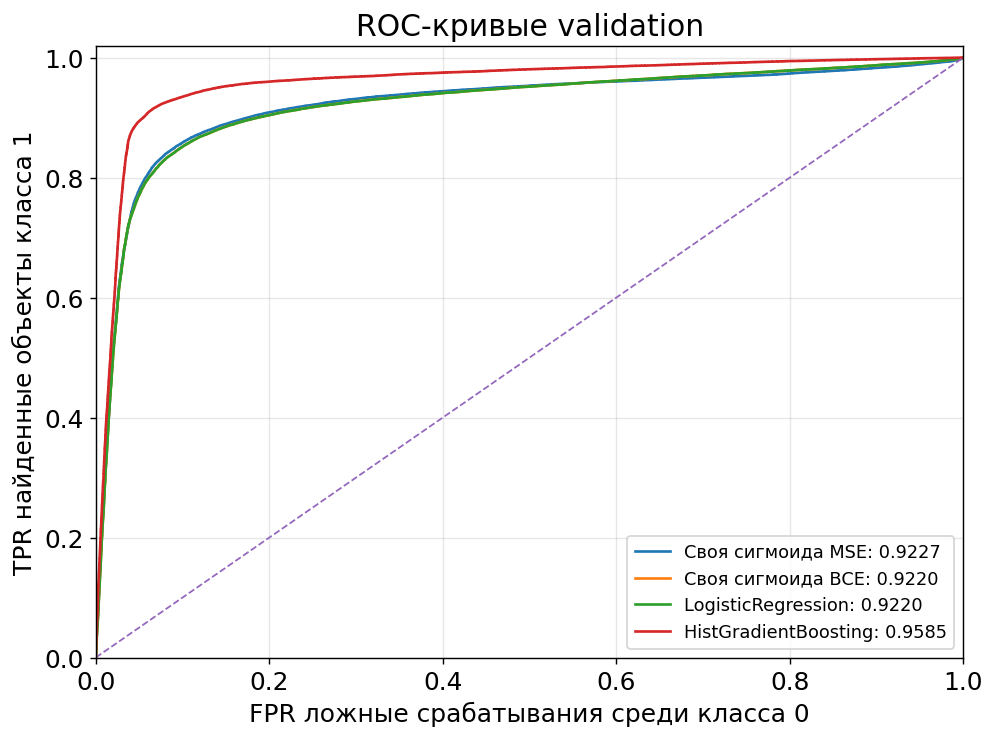

In [39]:
best_name = comparison.index[0]  # Фиксируем выбор по validation.
best_model = models[best_name]
selected_names = list(dict.fromkeys([
    "Своя сигмоида MSE", "Своя сигмоида BCE", "LogisticRegression", best_name
]))
plt.figure(figsize=(8, 6))
for name in selected_names:
    p = validation_probabilities[name]
    fpr, tpr, _ = roc_curve(y_val, p)
    plt.plot(fpr, tpr, label=f"{name}: {roc_auc_score(y_val, p):.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.xlabel("FPR ложные срабатывания среди класса 0")
plt.ylabel("TPR найденные объекты класса 1")
plt.title("ROC-кривые validation")
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Насколько можно доверять вероятностям

Разобьём объекты на группы по предсказанной вероятности и сравним среднюю вероятность со средней меткой.

Выберем группы с примерно одинаковым числом объектов (`strategy="quantile"`). 

См. [документацию по вероятностной калибровке](https://scikit-learn.org/stable/modules/calibration.html).

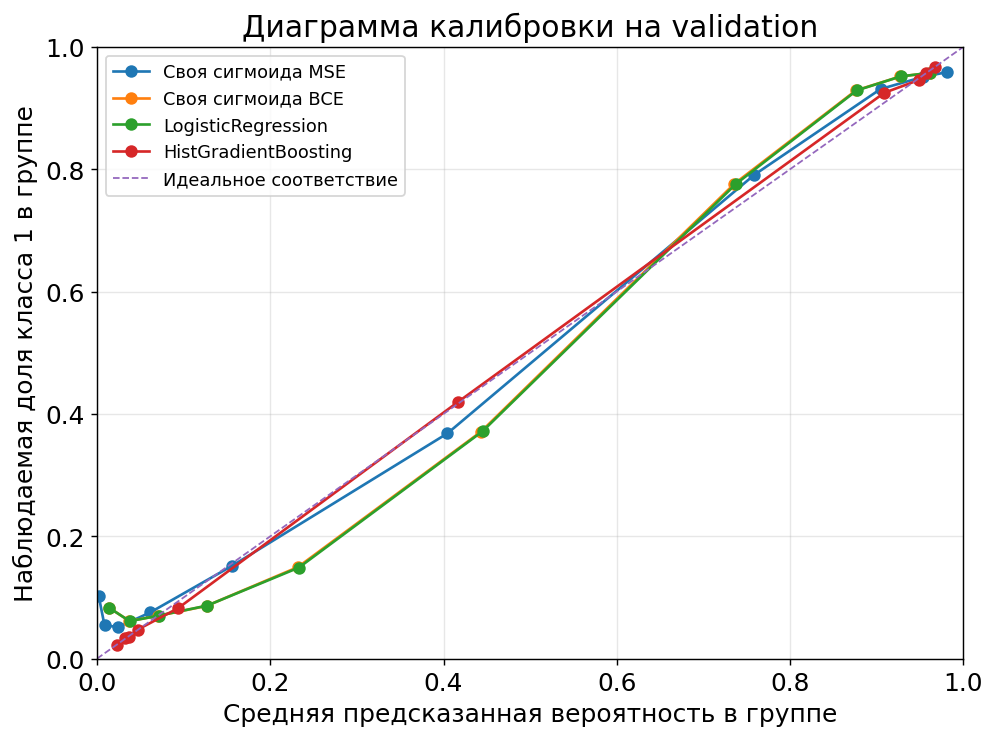

In [40]:
plt.figure(figsize=(8, 6))
for name in selected_names:
    observed_rate, mean_probability = calibration_curve(
        y_val, validation_probabilities[name], n_bins=10, strategy="quantile"
    )
    plt.plot(mean_probability, observed_rate, marker="o", label=name)
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Идеальное соответствие")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("Средняя предсказанная вероятность в группе")
plt.ylabel("Наблюдаемая доля класса 1 в группе")
plt.title("Диаграмма калибровки на validation")
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Один и тот же AUC — разные вероятности

Возведём прогнозы лидера в третью степень. Это строго возрастающее преобразование на [0, 1], поэтому порядок объектов не меняется. ROC-AUC остаётся прежним, а сами вероятности и вероятностные ошибки меняются.

In [41]:
p_original = validation_probabilities[best_name]
p_transformed = p_original ** 3
probability_demo = pd.DataFrame({
    "Исходные вероятности": evaluate_probabilities(y_val, p_original),
    "Вероятности в кубе": evaluate_probabilities(y_val, p_transformed),
}).T[["ROC-AUC", "Log loss", "Brier", "F1"]]

display(probability_demo.round(5))

np.testing.assert_allclose(
    roc_auc_score(y_val, p_original), roc_auc_score(y_val, p_transformed), atol=1e-12
)

,ROC-AUC,Log loss,Brier,F1
Исходные вероятности,0.95853,0.22761,0.06081,0.91496
Вероятности в кубе,0.95853,0.39872,0.07687,0.90078


## Распределение вероятностей по известным классам

Метки принимают только два значения, а разумные вероятности могут лежать между ними. 

На графике важно увидеть, как различаются распределения прогнозов у положительных и отрицательных объектов.

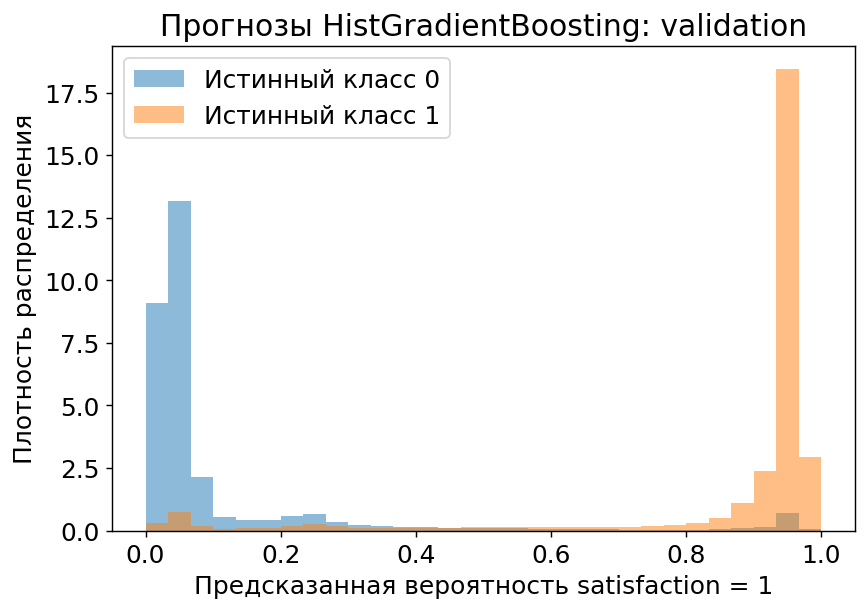

In [42]:
plt.figure()
for label in [0, 1]:
    plt.hist(p_original[y_val == label], bins=np.linspace(0, 1, 31), density=True,
             alpha=0.5, label=f"Истинный класс {label}")
plt.xlabel("Предсказанная вероятность satisfaction = 1")
plt.ylabel("Плотность распределения")
plt.title(f"Прогнозы {best_name}: validation")
plt.legend()
plt.tight_layout()
plt.show()

# От вероятности к классу

Вероятностная модель и правило принятия решения — разные части системы. 

При пороге $t$ положительный класс выбираем, когда $p\ge t$. 

Порог 0.5 естественен для минимизации числа ошибок при корректных вероятностях и одинаковой цене ложноположительной и ложноотрицательной ошибок. 

Он не обязан максимизировать F1.

$$\mathrm{Precision}=\frac{TP}{TP+FP},\qquad
\mathrm{Recall}=\frac{TP}{TP+FN},\qquad
F_1=\frac{2TP}{2TP+FP+FN}.$$

Снижение порога обычно увеличивает recall, но precision не обязана меняться строго монотонно. 

Для демонстрации выберем порог, максимизирующий F1 **только на validation**. Его качество затем проверим на отложенной выборке. 

См. [раздел sklearn о настройке порога](https://scikit-learn.org/stable/modules/classification_threshold.html).

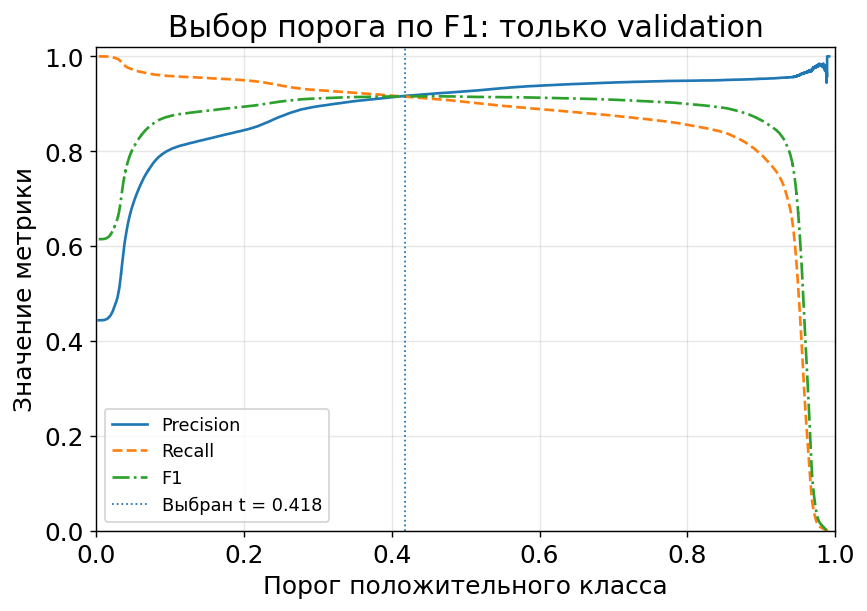

,Accuracy,Precision,Recall,F1
Порог 0.5,0.9255,0.9264,0.9038,0.915
Порог 0.4180,0.9256,0.9168,0.9153,0.916


In [43]:
precision_curve, recall_curve, threshold_values = precision_recall_curve(y_val, p_original)
# Последняя точка precision/recall не имеет соответствующего порога.
f1_curve = 2 * precision_curve[:-1] * recall_curve[:-1] / np.maximum(
    precision_curve[:-1] + recall_curve[:-1], 1e-15
)
threshold_table = pd.DataFrame({
    "threshold": threshold_values,
    "precision": precision_curve[:-1],
    "recall": recall_curve[:-1],
    "F1": f1_curve,
})
threshold_table["distance_to_0.5"] = np.abs(threshold_table["threshold"] - 0.5)
best_threshold_row = threshold_table.sort_values(
    ["F1", "distance_to_0.5"], ascending=[False, True]
).iloc[0]
best_threshold = float(best_threshold_row["threshold"])

plt.figure()
plt.plot(threshold_values, precision_curve[:-1], label="Precision")
plt.plot(threshold_values, recall_curve[:-1], label="Recall", linestyle="--")
plt.plot(threshold_values, f1_curve, label="F1", linestyle="-.")
plt.axvline(best_threshold, linestyle=":", linewidth=1, label=f"Выбран t = {best_threshold:.3f}")
plt.xlabel("Порог положительного класса")
plt.ylabel("Значение метрики")
plt.title("Выбор порога по F1: только validation")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

validation_threshold_comparison = pd.DataFrame({
    "Порог 0.5": evaluate_probabilities(y_val, p_original, 0.5),
    f"Порог {best_threshold:.4f}": evaluate_probabilities(y_val, p_original, best_threshold),
}).T[["Accuracy", "Precision", "Recall", "F1"]]
display(validation_threshold_comparison.round(4))

# Финальная проверка на отложенной выборке

Теперь получим предсказания на отложенной выборке. 

Покажем также ранее обученные модели в порядке, заданном валидационным сравнением.

Прогон модели по отложенной выборке даёт только одну оценку. Повторный подбор решений после просмотра этих ответов превратит её в ещё одну валидацию.

In [44]:
X_holdout_raw = df_holdout[feature_columns]
y_holdout = df_holdout[TARGET].to_numpy()
X_holdout = np.ascontiguousarray(
    preprocessor.transform(make_features(X_holdout_raw)), dtype=np.float64
)
holdout_probabilities = {}
holdout_rows = []
for name in comparison.index:
    p = models[name].predict_proba(X_holdout)[:, 1]
    holdout_probabilities[name] = p
    holdout_rows.append({"Модель": name, **evaluate_probabilities(y_holdout, p)})
holdout_metrics = pd.DataFrame(holdout_rows).set_index("Модель")
display(holdout_metrics.round(4))
holdout_metrics.to_csv("holdout_metrics.csv", encoding="utf-8-sig")

p_holdout = holdout_probabilities[best_name]
holdout_threshold_comparison = pd.DataFrame({
    "Порог 0.5": evaluate_probabilities(y_holdout, p_holdout, 0.5),
    f"Порог {best_threshold:.4f} с validation": evaluate_probabilities(y_holdout, p_holdout, best_threshold),
}).T
display(holdout_threshold_comparison.round(4))
holdout_threshold_comparison.to_csv("threshold_metrics.csv", encoding="utf-8-sig")

,ROC-AUC,AP,Log loss,Brier,Accuracy,Precision,Recall,F1
Модель,,,,,,,,
HistGradientBoosting,0.9568,0.9403,0.2324,0.0623,0.9235,0.9252,0.9004,0.9126
RandomForest,0.9551,0.9382,0.2398,0.0646,0.9211,0.9185,0.9021,0.9102
DecisionTree,0.9489,0.9268,0.2606,0.0722,0.9094,0.9145,0.8779,0.8958
Своя сигмоида MSE,0.9210,0.9106,0.3712,0.0952,0.8815,0.8852,0.8422,0.8631
Своя сигмоида BCE,0.9206,0.9090,0.3465,0.0979,0.8784,0.8757,0.8460,0.8606
LogisticRegression,0.9206,0.9090,0.3464,0.0980,0.8783,0.8750,0.8466,0.8606
GaussianNB,0.9073,0.8943,1.3214,0.1372,0.8506,0.8381,0.8221,0.8300
Dummy: доля класса,0.5000,0.4436,0.6868,0.2468,0.5564,0.0000,0.0000,0.0000


,ROC-AUC,AP,Log loss,Brier,Accuracy,Precision,Recall,F1
Порог 0.5,0.9568,0.9403,0.2324,0.0623,0.9235,0.9252,0.9004,0.9126
Порог 0.4180 с validation,0.9568,0.9403,0.2324,0.0623,0.9233,0.9153,0.9115,0.9134


## Матрица ошибок своими руками

Посчитаем TP, FP, FN и TN через логические маски. 

При отсутствии положительных прогнозов precision определим как ноль.

TP           56574.000000
FP            5234.000000
FN            5494.000000
TN           72625.000000
Accuracy         0.923331
Precision        0.915318
Recall           0.911484
F1               0.913397
Name: Ручной расчёт метрик, dtype: float64

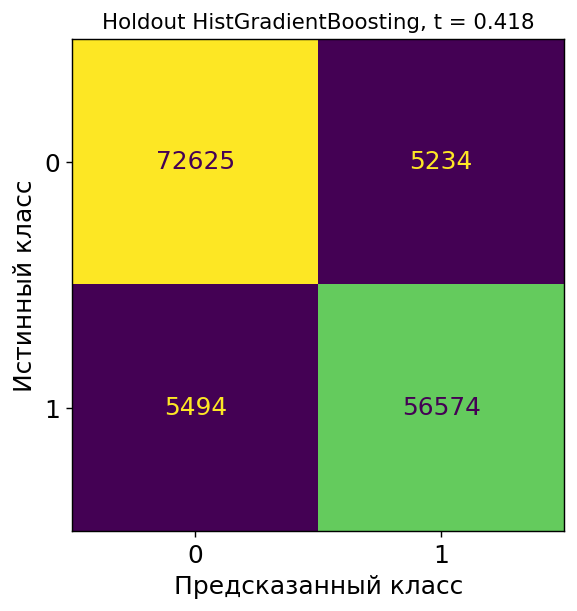

In [45]:
def manual_confusion_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).ravel().astype(int)
    y_pred = np.asarray(y_pred).ravel().astype(int)
    if len(y_true) != len(y_pred) or not np.isin(y_true, [0, 1]).all() or not np.isin(y_pred, [0, 1]).all():
        raise ValueError("Нужны бинарные массивы одинаковой длины.")
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    safe_divide = lambda numerator, denominator: numerator / denominator if denominator else 0.0
    return {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Accuracy": safe_divide(tp + tn, tp + fp + fn + tn),
        "Precision": safe_divide(tp, tp + fp),
        "Recall": safe_divide(tp, tp + fn),
        "F1": safe_divide(2 * tp, 2 * tp + fp + fn),
    }

y_holdout_pred = (p_holdout >= best_threshold).astype(int)
manual_metrics = manual_confusion_metrics(y_holdout, y_holdout_pred)
display(pd.Series(manual_metrics, name="Ручной расчёт метрик"))
expected_metrics = evaluate_probabilities(y_holdout, p_holdout, best_threshold)
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    np.testing.assert_allclose(manual_metrics[metric], expected_metrics[metric])
assert sum(manual_metrics[k] for k in ["TP", "FP", "FN", "TN"]) == len(y_holdout)

matrix = confusion_matrix(y_holdout, y_holdout_pred, labels=[0, 1])
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111)
ConfusionMatrixDisplay(matrix, display_labels=[0, 1]).plot(ax=ax, colorbar=False, values_format="d")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title(f"Holdout {best_name}, t = {best_threshold:.3f}", fontsize=12)
plt.tight_layout()
plt.show()

# Что означают веса сигмоидальной модели

Положительный вес повышает линейный логит при увеличении соответствующего признака и фиксированных остальных входах, отрицательный — понижает. 

Для стандартизированного числового признака единица означает одно обучающее стандартное отклонение, а для one-hot-признака — переключение индикатора.

При полном one-hot-кодировании для сравнения двух категорий одного признака нужно рассматривать **разность** их коэффициентов. Сам по себе вес категории не является эффектом относительно явно выделенной базовой категории. Коррелирующие признаки могут перераспределять веса, поэтому это просто описание модели, а не причинное объяснение поведения пассажиров.

In [46]:
coefficients = pd.DataFrame({
    "Своя MSE": model_mse.coef_[0],
    "Своя BCE": model_bce.coef_[0],
    "sklearn BCE": models["LogisticRegression"].coef_[0],
}, index=feature_names)
strongest = coefficients["Своя BCE"].abs().nlargest(12).index

display(coefficients.loc[strongest].round(4))

print("Свободный коэффициент своей MSE-модели", round(model_mse.intercept_[0], 4))
print("Свободный коэффициент своей BCE-модели", round(model_bce.intercept_[0], 4))
print("Свободный коэффициент sklearn BCE", round(models["LogisticRegression"].intercept_[0], 4))

,Своя MSE,Своя BCE,sklearn BCE
Type of Travel_Personal Travel,-1.7410,-1.3967,-1.1498
Customer Type_disloyal Customer,-1.4359,-1.1446,-0.9046
Type of Travel_Business travel,1.0388,0.9013,1.1498
Online boarding,1.3710,0.8316,0.8310
Customer Type_Loyal Customer,0.7425,0.6595,0.9046
Inflight wifi service,0.5588,0.4176,0.4182
Class_Eco Plus,-0.5172,-0.4047,-0.2468
On-board service,0.4288,0.3736,0.3720
Checkin service,0.4357,0.3639,0.3630
Class_Eco,-0.4170,-0.3605,-0.1973


Свободный коэффициент своей MSE-модели -1.0805
Свободный коэффициент своей BCE-модели -0.7591
Свободный коэффициент sklearn BCE -1.6541


# Предсказание для одного пассажира



Возьмём строку из отложенной выборки, не изменяя порядок признаков. 

In [47]:
passenger_rownum = 65

one_passenger = X_holdout_raw.iloc[[passenger_rownum]].copy()
one_transformed = preprocessor.transform(make_features(one_passenger))
one_probability = best_model.predict_proba(one_transformed)[0]


display(one_passenger.T.rename(columns={one_passenger.index[0]: "Значение"}))

,Значение
Age,58
Flight Distance,867
Inflight wifi service,2
Departure/Arrival time convenient,2
Ease of Online booking,2
Gate location,2
Food and drink,2
Online boarding,2
Seat comfort,2
Inflight entertainment,2


In [48]:
display(pd.Series({
    "id": int(df_holdout[ID_COL].iloc[passenger_rownum]),
    "P(класс 0)": one_probability[0],
    "P(класс 1)": one_probability[1],
    "Класс при пороге 0.5": int(one_probability[1] >= 0.5),
    "Класс при выбранном пороге": int(one_probability[1] >= best_threshold),
    "Известная метка": int(y_holdout[0]),
}, name="Ответ для одного пассажира"))

id                            538751.000000
P(класс 0)                         0.949769
P(класс 1)                         0.050231
Класс при пороге 0.5               0.000000
Класс при выбранном пороге         0.000000
Известная метка                    0.000000
Name: Ответ для одного пассажира, dtype: float64

In [49]:
# Точки не одинаковых предсказаний
passengers = X_holdout_raw.copy()
full_transformed = preprocessor.transform(make_features(passengers))
full_probability = best_model.predict_proba(full_transformed)

In [50]:
not_eq_preds = passengers[np.abs((full_probability[:, 1] >= 0.5) ^ (full_probability[:, 1] >= best_threshold))]
not_eq_preds

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
214027,27,1020,4,5,4,5,5,4,5,5,5,3,5,4,5,0,0.0,Male,disloyal Customer,Business travel,Business
631097,40,2542,2,3,3,3,1,4,4,4,5,4,2,1,1,0,0.0,Male,Loyal Customer,Business travel,Business
134748,23,479,4,4,4,4,4,4,4,4,2,4,4,1,4,0,0.0,Female,Loyal Customer,Business travel,Business
389992,22,776,5,4,4,4,4,4,5,5,2,3,4,4,5,0,0.0,Male,disloyal Customer,Business travel,Eco
157434,40,110,4,4,0,3,5,0,5,5,1,3,1,2,5,0,0.0,Male,Loyal Customer,Personal Travel,Eco
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
372145,27,590,4,4,4,5,5,4,5,5,4,3,5,3,5,0,0.0,Female,disloyal Customer,Business travel,Business
575808,41,370,4,4,4,4,4,4,4,4,4,3,4,3,4,0,0.0,Male,disloyal Customer,Business travel,Business
40896,43,874,4,2,2,2,4,4,4,4,2,3,4,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
694752,27,1013,4,4,4,4,5,4,5,5,4,4,4,3,5,0,0.0,Male,disloyal Customer,Business travel,Business


In [51]:
one_passenger = X_holdout_raw[X_holdout_raw.index == 575808].copy()
one_transformed = preprocessor.transform(make_features(one_passenger))
one_probability = best_model.predict_proba(one_transformed)[0]


display(one_passenger.T.rename(columns={one_passenger.index[0]: "Значение"}))

display(pd.Series({
    "id": int(df_holdout[ID_COL].iloc[passenger_rownum]),
    "P(класс 0)": one_probability[0],
    "P(класс 1)": one_probability[1],
    "Класс при пороге 0.5": int(one_probability[1] >= 0.5),
    "Класс при выбранном пороге": int(one_probability[1] >= best_threshold),
    "Известная метка": int(y_holdout[0]),
}, name="Ответ для одного пассажира"))

,Значение
Age,41
Flight Distance,370
Inflight wifi service,4
Departure/Arrival time convenient,4
Ease of Online booking,4
Gate location,4
Food and drink,4
Online boarding,4
Seat comfort,4
Inflight entertainment,4


id                            538751.000000
P(класс 0)                         0.567459
P(класс 1)                         0.432541
Класс при пороге 0.5               0.000000
Класс при выбранном пороге         1.000000
Известная метка                    0.000000
Name: Ответ для одного пассажира, dtype: float64

# Переобучение и предсказание для Kaggle

После оценки качества обучим выбранную конфигурацию заново. 
При `FULL_REFIT = True` используем все строки исходного `train.csv`, включая ранее отложенные части и строки вне демонстрационной подвыборки. 

Метрики выше относятся к предыдущим моделям, а **не к этому финальному переобучению**.

Соберём построчные преобразования, предобработку и модель в единый `Pipeline`. Новый экземпляр заполнения пропусков, кодировщика и масштабирования обучится на финальной обучающей выборке. Файл `test.csv` участвует только в `predict_proba`, никогда в `fit`.

Кроме победителя, переобучим собственную BCE-модель. Получатся `submission.csv` и `submission_selfmade.csv`. 

Для новой обучающей выборки у `LogisticRegression` пересчитаем `C`, чтобы сохранить прежнее значение $\lambda$. Для собственной модели оставим те же эпохи и шаг.

In [52]:
final_train = df if FULL_REFIT else df_work
X_final_raw = final_train[feature_columns]
y_final = final_train[TARGET].to_numpy()
X_kaggle_raw = df_test[feature_columns]


def make_final_pipeline(model, n_training_rows):
    classifier = clone(model)
    if isinstance(classifier, LogisticRegression):
        classifier.set_params(C=1.0 / (n_training_rows * L2))
    return Pipeline([
        ("features", FunctionTransformer(make_features, validate=False)),
        ("preprocess", clone(preprocessor)),
        ("model", classifier),
    ])

start = perf_counter()
final_pipeline = make_final_pipeline(best_model, len(y_final))
final_pipeline.fit(X_final_raw, y_final)
final_fit_seconds = perf_counter() - start
assert np.array_equal(final_pipeline.classes_, [0, 1])

# Пакетный инференс не создаёт сразу большую закодированную матрицу всего test.
def predict_in_batches(pipeline, frame, batch_size=50_000):
    pieces = [
        pipeline.predict_proba(frame.iloc[start:start + batch_size])[:, 1]
        for start in range(0, len(frame), batch_size)
    ]
    return np.concatenate(pieces)

kaggle_probability = predict_in_batches(final_pipeline, X_kaggle_raw)
print(f"Финальная модель: {best_name}")
print(f"Обучающих строк: {len(y_final):,}; время fit: {final_fit_seconds:.2f} с")
print(f"Предсказаний для test.csv: {len(kaggle_probability):,}")

Финальная модель: HistGradientBoosting
Обучающих строк: 699,635; время fit: 25.96 с
Предсказаний для test.csv: 299,844


In [53]:
if best_name == "Своя сигмоида BCE":
    final_selfmade_pipeline = final_pipeline
    kaggle_probability_selfmade = kaggle_probability.copy()
else:
    start = perf_counter()
    final_selfmade_pipeline = make_final_pipeline(model_bce, len(y_final))
    final_selfmade_pipeline.fit(X_final_raw, y_final)
    kaggle_probability_selfmade = predict_in_batches(final_selfmade_pipeline, X_kaggle_raw)
    print(f"Финальное обучение своей BCE-модели: {perf_counter() - start:.2f} с (включая прогноз)")

Финальное обучение своей BCE-модели: 25.30 с (включая прогноз)


## Сохраняем вероятности, сохраняя id и порядок строк

Строим файл по шаблону `sample_submission.csv`. Проверим число строк, порядок идентификаторов, отсутствие пропусков и диапазон вероятностей. `index=False` не даёт pandas добавить лишнюю колонку.

Классы при пороге 0.5 сохраним отдельно, только для учебной иллюстрации. Этот файл не предназначен для отправки в соревнование. Порог, выбранный на validation для старой модели, не объявляем заново проверенным для переобученной модели.

In [54]:
def make_submission(probabilities, filename):
    probabilities = np.asarray(probabilities, dtype=float).ravel()
    if len(probabilities) != len(sample_submission):
        raise ValueError("Число предсказаний не совпадает с шаблоном.")
    if not np.isfinite(probabilities).all() or not np.all((probabilities >= 0) & (probabilities <= 1)):
        raise ValueError("Обнаружены некорректные вероятности.")
    result = sample_submission.copy()
    result[TARGET] = probabilities
    result.to_csv(filename, index=False)
    return result

submission = make_submission(kaggle_probability, "submission.csv")
submission_selfmade = make_submission(kaggle_probability_selfmade, "submission_selfmade.csv")

example_classes = submission[[ID_COL]].copy()
example_classes["predicted_class_at_0_5"] = (kaggle_probability >= 0.5).astype(int)
example_classes.to_csv("example_classes_not_for_submission.csv", index=False)

display(submission.head(10))
print("Уникальных значений вероятности", submission[TARGET].nunique())

,id,satisfaction
0,699635,0.206357
1,699636,0.907718
2,699637,0.895247
3,699638,0.069926
4,699639,0.048174
5,699640,0.962145
6,699641,0.032242
7,699642,0.936963
8,699643,0.961921
9,699644,0.028828


Уникальных значений вероятности 294923


# Самостоятельная работа

**Другой порог.** Задайте требование к recall, например не ниже 0.9. Выберите порог на validation и проверьте precision и recall на holdout. Не меняйте порог после просмотра holdout.

**Другие признаки.** Закодируйте оценки сервиса через one-hot, а не как числовые величины. Сравните логистическую регрессию с исходной версией на том же разбиении. Проверьте, улучшилось ли только ранжирование или также log loss и Brier.

**Обучение своей модели.** Измените шаг, размер пакета и число эпох. Объясните, чем различаются недостаточная сходимость и ограниченность самой линейной модели. Сверьте BCE-цель с `LogisticRegression` при одинаковой регуляризации.

**Более строгая оценка.** Замените одиночную validation на `StratifiedKFold`. На каждом фолде заново обучайте весь `Pipeline`, включая кодировщик и масштабирование. Для дальнейших экспериментов оставьте новый финальный holdout, иначе уже просмотренные данные перестанут быть независимой проверкой.